In [48]:
#importar o Pandas e carregar o arquivo
import pandas as pd
dados = pd.read_csv('techgear.csv')

print('PRIMEIRAS LINHAS')
print('\n')
print(dados.head())
print('INFORMAÇÃO')
print('\n')
print(dados.info())
print('DESCRIÇÃO')
print('\n')
print(dados.describe())
print('QUANTIDADE DUPLICADAS')
print(dados.duplicated().sum())
#verificar quantidades de compras e não compras
print(dados['comprou'].value_counts())

#calcular em porcentagens
print(dados["comprou"].value_counts(normalize=True)*100)

#avaliação  dos produtos
print(dados['avaliacao_estrelas'].describe())

#remover dados duplicados
dados=dados.drop_duplicates()
print(dados.duplicated().sum())

#separar as variaveis
x=dados.drop('comprou',axis=1)
y=dados['comprou']

#caracteristicas de produtos
print('variavel de entrada')
print(x.head())
print('\n')
#resultado das compras
print('variavel de saida')
print(y.head())




PRIMEIRAS LINHAS


   preco_reais  avaliacao_estrelas  frete_gratis  desconto_percentual  comprou
0       218.23                 3.9             0                    5        0
1       468.19                 4.0             1                    0        0
2       326.45                 5.0             0                   10        0
3       377.48                 3.8             1                   40        0
4        77.52                 5.0             0                   30        1
INFORMAÇÃO


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   preco_reais          5000 non-null   float64
 1   avaliacao_estrelas   5000 non-null   float64
 2   frete_gratis         5000 non-null   int64  
 3   desconto_percentual  5000 non-null   int64  
 4   comprou              5000 non-null   int64  
dtypes: float64(2), int64(3)
memory us

In [49]:
#Dividir os dados em treinamento e teste

from sklearn.model_selection import train_test_split
X_treino, X_teste, y_treino, y_teste = train_test_split(
  x,  # Usando o 'x' minúsculo que foi definido na célula anterior
  y,
  test_size=0.2,
  random_state=42,
  stratify=y
)

print("treinamento:", X_treino.shape)
print("teste:", X_teste.shape)

print("compras no  treinamento:")
print(y_treino.value_counts())

print("compras no teste:")
print(y_teste.value_counts())

treinamento: (3999, 4)
teste: (1000, 4)
compras no  treinamento:
comprou
0    3239
1     760
Name: count, dtype: int64
compras no teste:
comprou
0    810
1    190
Name: count, dtype: int64


In [50]:
#treianemnto do modelo machine learnig
from sklearn.linear_model import LogisticRegression
modelo= LogisticRegression(max_iter=1000)

#treinar a inteligencia artificial
modelo.fit(X_treino,y_treino)

#primeiras previsões
previsoes=modelo.predict(X_teste)
print(previsoes)

[0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 0
 1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0
 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 1 0 1 0 1 0 1 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 1 1 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0
 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 1 1 0 0 1 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 1 0 1 1
 1 1 0 0 0 0 0 0 0 0 0 0 

In [51]:
#Vizualizar os primeiros  resultados

comparacao=pd.DataFrame({
    'real':y_teste.values,
    'previsto': previsoes

})

print(comparacao.head(10))

from sklearn.metrics import accuracy_score # calcula a acuaria
from sklearn.metrics import confusion_matrix # mostra acertos e erro
from sklearn.metrics import classification_report # apresenta metricas detalhadas

#acuracia previsões que o modelo  acertou  ao total das previsões
acuracia= accuracy_score (y_teste, previsoes)
print('\n')
print("acuracia:", acuracia)

matriz= confusion_matrix(y_teste, previsoes)
print(matriz)

   real  previsto
0     0         0
1     0         1
2     0         0
3     0         0
4     0         0
5     0         0
6     1         1
7     0         0
8     0         0
9     0         0


acuracia: 0.94
[[785  25]
 [ 35 155]]


In [52]:
#785 Acerto ! não compraria e não  comprou
#25 erro! compraria e não  comprou
#35 erro! não  compraria e comprou
#155 Acerto! compraria e comprou

relatorio = classification_report(y_teste, previsoes)
print(relatorio)


              precision    recall  f1-score   support

           0       0.96      0.97      0.96       810
           1       0.86      0.82      0.84       190

    accuracy                           0.94      1000
   macro avg       0.91      0.89      0.90      1000
weighted avg       0.94      0.94      0.94      1000



In [59]:
novos_produtos=pd.DataFrame({
    'preco_reais':[2600,89,1200],
    'avaliacao_estrelas':[4.8,4.5,3.5],
    'frete_gratis':[1,1,0],
    'desconto_percentual':[20,10,5]

})
resultado = modelo.predict(novos_produtos)
print(resultado)

probabilidades =modelo. predict_proba(novos_produtos)
print(probabilidades)

tabela_resultados = novos_produtos.copy()
tabela_resultados['previsao']= resultado
tabela_resultados['probabilidade_de_compra']= (
    probabilidades[:,1]*100

  )
print(tabela_resultados)

[0 0 0]
[[1.00000000e+00 2.67096850e-45]
 [5.33275803e-01 4.66724197e-01]
 [1.00000000e+00 7.37124677e-24]]
   preco_reais  avaliacao_estrelas  frete_gratis  desconto_percentual  \
0         2600                 4.8             1                   20   
1           89                 4.5             1                   10   
2         1200                 3.5             0                    5   

   previsao  probabilidade_de_compra  
0         0             2.670968e-43  
1         0             4.667242e+01  
2         0             7.371247e-22  


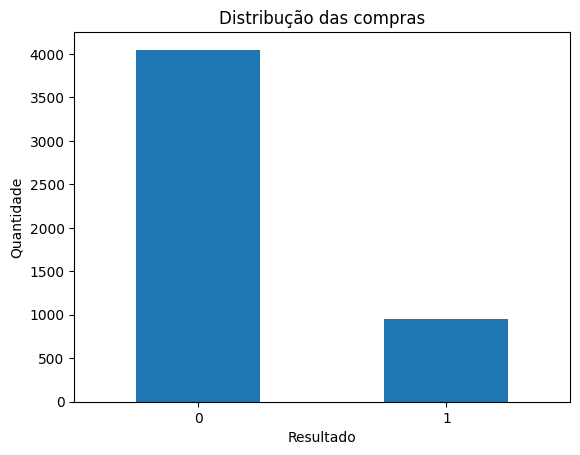

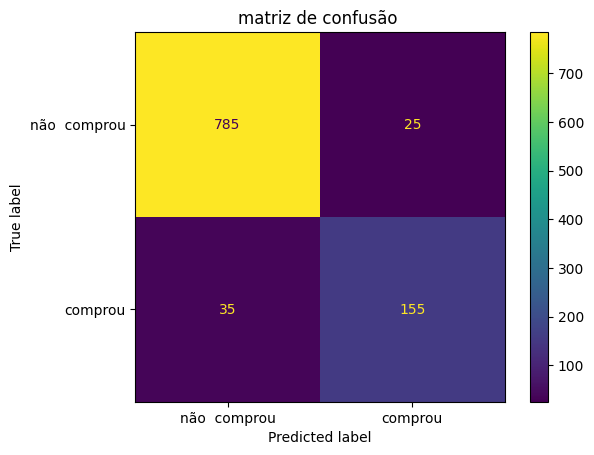

--- Relatorio Final ---
acuracia:94.00%

Relatorio de Classificação 
              precision    recall  f1-score   support

não comprou        0.96      0.97      0.96       810
    comprou        0.86      0.82      0.84       190

    accuracy                           0.94      1000
   macro avg       0.91      0.89      0.90      1000
weighted avg       0.94      0.94      0.94      1000



In [65]:
#graficos
import matplotlib.pyplot as plt

contagem= dados ['comprou'].value_counts()

contagem.plot(kind='bar')

plt.title("Distribução das compras")
plt.xlabel("Resultado")
plt.ylabel('Quantidade')
plt.xticks(rotation=0) #deixa os nomes na horizontal

plt.show()

from  sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes,
    display_labels=['não  comprou','comprou']

)
plt.title("matriz de confusão ")
plt.show()

from sklearn.metrics import accuracy_score, classification_report

acuracia=accuracy_score(y_teste,previsoes)

print("--- Relatorio Final ---")

print(f'acuracia:{acuracia *100:.2f}%')

print('\nRelatorio de Classificação ')

print (classification_report(
       y_teste,
       previsoes,
       target_names=['não comprou ', ' comprou ']

))